# Notebook 03 — Clasificación temporal y política de alertas

**Problema 7.** Predecir, dos horas antes de la salida, si un vuelo saldrá con al menos 15 minutos de retraso, $Y=\mathbb 1\{\texttt{min\_retraso}\ge15\}$, y elegir una política de alertas bajo restricciones operativas.

| Conjunto | Uso |
|---|---|
| Entrenamiento (primer 60 %) | Comparar modelos con validación cruzada temporal |
| Validación (60 %–80 %) | Diagnosticar probabilidades y elegir la política |
| Prueba (último 20 %) | Una única evaluación al final |

La regresión logística (con y sin pesos de clase) es la implementación propia de `modelos.py`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, auc, average_precision_score, brier_score_loss,
                             confusion_matrix, f1_score, log_loss, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from modelos import SEMILLA, RegresionLogisticaGD

RESULTADOS = Path("resultados")
PARAMETROS = RESULTADOS / "parametros"
PARAMETROS.mkdir(parents=True, exist_ok=True)
SEED = SEMILLA     # nombre que usa generar_vuelos como semilla por defecto
GAP = 24           # una fila = una hora; 24 filas = un día
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

## Datos

`generar_vuelos` es la función del notebook de clasificación de clase, copiada **sin modificar su mecanismo**. Se llama con `n=9600, seed=2026`. Internamente calcula una probabilidad generadora, pero esa probabilidad no se devuelve y no se usa: el modelo solo ve los predictores y la etiqueta observada.

In [2]:
# Reutilizado de clase: generar_vuelos, copiada sin cambios (el enunciado exige no modificarla).
# Mejoras: ninguna en la función; se agrega afuera un id por vuelo y la etiqueta.
def generar_vuelos(n=9600, seed=SEED):
    rng = np.random.default_rng(seed)
    fecha = pd.date_range('2024-01-01', periods=n, freq='h')
    hora = ((fecha + pd.Timedelta(hours=2)).hour).to_numpy()
    progreso = np.linspace(0, 1, n)
    aerolinea = rng.choice(['Aero_A', 'Aero_B', 'Aero_C'], n, p=[0.50, 0.30, 0.20])
    origen = rng.choice(['BOG', 'MDE', 'CLO', 'CTG'], n)
    distancia = rng.uniform(200, 1800, n)
    lluvia = rng.gamma(shape=1.2, scale=2.0, size=n)
    viento = np.clip(rng.normal(15, 6, n), 0, 45)
    ocupacion = np.clip(rng.normal(77, 12, n), 25, 100)
    trafico = np.clip(rng.normal(45 + 10 * progreso, 13, n), 5, 100)
    # Probabilidad del simulador: combina factores conocidos antes de la salida.
    logit = (
        -5.3 + 1.1 * (trafico - 45) / 13
        + 0.8 * (lluvia - 2.4) / 2.2 + 0.7 * (viento - 15) / 6
        + 0.35 * (ocupacion - 77) / 12 + 0.55 * (hora >= 17)
        + 0.40 * (origen == 'BOG') + 0.45 * (aerolinea == 'Aero_C')
    )
    probabilidad_generadora = 1 / (1 + np.exp(-logit))
    # La etiqueta se sortea: vuelos similares pueden tener resultados distintos.
    positivo = rng.binomial(1, probabilidad_generadora)
    retraso = np.where(positivo == 1, rng.integers(15, 181, n), rng.integers(-10, 15, n))
    datos = pd.DataFrame({
        'fecha_prediccion': fecha, 'hora_salida': hora,
        'distancia_km': distancia, 'lluvia_pronosticada_mm': lluvia,
        'viento_pronosticado_kmh': viento, 'ocupacion_programada_pct': ocupacion,
        'trafico_programado': trafico, 'aerolinea': aerolinea,
        'origen': origen, 'min_retraso': retraso,
    })
    # Los faltantes afectan a predictores, nunca a la etiqueta observada.
    for columna in ['lluvia_pronosticada_mm', 'viento_pronosticado_kmh',
                    'ocupacion_programada_pct', 'aerolinea']:
        datos.loc[rng.random(n) < 0.06, columna] = np.nan
    return datos


vuelos = generar_vuelos(n=9600, seed=2026).sort_values("fecha_prediccion").reset_index(drop=True)
vuelos.insert(0, "id_vuelo", np.arange(1, len(vuelos) + 1))     # id estable en orden cronológico
vuelos["retrasado"] = (vuelos["min_retraso"] >= 15).astype(int)

NUMERICAS = ["hora_salida", "distancia_km", "lluvia_pronosticada_mm", "viento_pronosticado_kmh",
             "ocupacion_programada_pct", "trafico_programado"]
CATEGORICAS = ["aerolinea", "origen"]
PREDICTORES = NUMERICAS + CATEGORICAS
vuelos.head()

,id_vuelo,fecha_prediccion,hora_salida,distancia_km,lluvia_pronosticada_mm,viento_pronosticado_kmh,ocupacion_programada_pct,trafico_programado,aerolinea,origen,min_retraso,retrasado
0,1,2024-01-01 00:00:00,2,862.8348,2.2192,5.2833,69.7092,39.1817,Aero_A,MDE,11,0
1,2,2024-01-01 01:00:00,3,326.8961,4.1699,17.0507,62.3248,35.4055,Aero_B,CLO,0,0
2,3,2024-01-01 02:00:00,4,418.3571,0.7270,9.7587,67.7305,22.5180,Aero_A,MDE,1,0
3,4,2024-01-01 03:00:00,5,1415.5487,1.0526,NaN,72.9115,37.9272,Aero_A,CTG,4,0
4,5,2024-01-01 04:00:00,6,799.1430,0.6765,10.7799,68.0714,44.4690,Aero_A,BOG,9,0


## 7a. Diccionario, partición temporal y auditoría

### ¿Qué se conoce dos horas antes de la salida?

| Variable | Tipo | ¿Disponible 2 h antes? | Uso | Justificación |
|---|---|---|---|---|
| `fecha_prediccion` | fecha-hora | Sí | Solo ordenar y partir | Es el momento de la predicción; usarla como predictor convertiría la tendencia temporal en un atajo |
| `hora_salida` | entero (0–23) | Sí | Predictor | Hora programada del itinerario |
| `distancia_km` | numérica | Sí | Predictor | Distancia de la ruta programada |
| `lluvia_pronosticada_mm` | numérica | Sí | Predictor | Es un **pronóstico**, no la lluvia observada |
| `viento_pronosticado_kmh` | numérica | Sí | Predictor | Pronóstico meteorológico |
| `ocupacion_programada_pct` | numérica | Sí | Predictor | Reservas conocidas al momento de predecir |
| `trafico_programado` | numérica | Sí | Predictor | Tráfico planificado, no el observado |
| `aerolinea` | categórica | Sí | Predictor | Dato de la operación programada |
| `origen` | categórica | Sí | Predictor | Aeropuerto de salida programado |
| `min_retraso` | entera | **No** | Solo define $Y$ | Se observa después de la salida; incluirla sería fuga directa |

### Partición

Se usan los mismos cortes que en el notebook de clase:

- **Entrenamiento:** filas antes del corte del 60 %, excluyendo las 24 inmediatamente anteriores al corte.
- **Validación:** filas desde el corte del 60 % hasta el del 80 %, excluyendo las 24 inmediatamente anteriores al segundo corte.
- **Prueba:** filas desde el corte del 80 % hasta el final.

Cada fila es una hora. Las 24 filas excluidas antes de cada corte representan un día, bajo la hipótesis de que la etiqueta de un vuelo se conoce en menos de un día. Así, ninguna etiqueta del período anterior queda pendiente al iniciar el siguiente.

In [3]:
# Reutilizado de clase: separar_por_tiempo (cortes al 60 % y 80 % con exclusión de GAP filas).
# Mejoras: se registra el conjunto de cada id (incluidas las filas excluidas) y los rangos.
corte_1, corte_2 = int(len(vuelos) * 0.60), int(len(vuelos) * 0.80)
vuelos["conjunto"] = "prueba"
vuelos.loc[:corte_2 - 1, "conjunto"] = "validacion"
vuelos.loc[corte_2 - GAP:corte_2 - 1, "conjunto"] = "excluida (gap)"
vuelos.loc[:corte_1 - 1, "conjunto"] = "entrenamiento"
vuelos.loc[corte_1 - GAP:corte_1 - 1, "conjunto"] = "excluida (gap)"

entrenamiento = vuelos[vuelos["conjunto"] == "entrenamiento"].reset_index(drop=True)
validacion = vuelos[vuelos["conjunto"] == "validacion"].reset_index(drop=True)
prueba = vuelos[vuelos["conjunto"] == "prueba"].reset_index(drop=True)

# Separación temporal: más de 24 horas entre el final de un período y el inicio del siguiente.
for antes, despues in ((entrenamiento, validacion), (validacion, prueba)):
    assert despues["fecha_prediccion"].min() - antes["fecha_prediccion"].max() > pd.Timedelta(hours=GAP)
    assert antes["id_vuelo"].max() + GAP < despues["id_vuelo"].min()
assert not {"min_retraso", "retrasado", "fecha_prediccion"} & set(PREDICTORES)

vuelos[["id_vuelo", "fecha_prediccion", "conjunto"]].to_csv(RESULTADOS / "p7_particiones.csv", index=False)
rangos = vuelos.groupby("conjunto", sort=False).agg(
    n=("id_vuelo", "size"), id_min=("id_vuelo", "min"), id_max=("id_vuelo", "max"),
    inicio=("fecha_prediccion", "min"), fin=("fecha_prediccion", "max"))
rangos

,n,id_min,id_max,inicio,fin
conjunto,,,,,
entrenamiento,5736,1,5736,2024-01-01,2024-08-26 23:00:00
excluida (gap),48,5737,7680,2024-08-27,2024-11-15 23:00:00
validacion,1896,5761,7656,2024-08-28,2024-11-14 23:00:00
prueba,1920,7681,9600,2024-11-16,2025-02-03 23:00:00


### Auditoría en entrenamiento

Faltantes, tipos y distribuciones se revisan **solo en entrenamiento**. La prevalencia de validación y la de prueba no se calculan aquí.

In [4]:
X_ent, y_ent = entrenamiento[PREDICTORES], entrenamiento["retrasado"].to_numpy()

auditoria = pd.DataFrame({
    "tipo": X_ent.dtypes.astype(str),
    "faltantes": X_ent.isna().sum(),
    "% faltantes": 100 * X_ent.isna().mean(),
    "valores únicos": X_ent.nunique(),
})
display(auditoria.round(2))
display(X_ent[NUMERICAS].describe().T.round(2))
for col in CATEGORICAS:
    print(col, X_ent[col].value_counts(dropna=False).to_dict())
print(f"\nPrevalencia en entrenamiento: {y_ent.mean():.4f} ({y_ent.sum()} positivos de {len(y_ent)})")

,tipo,faltantes,% faltantes,valores únicos
hora_salida,int32,0,0.00,24
distancia_km,float64,0,0.00,5736
lluvia_pronosticada_mm,float64,359,6.26,5377
viento_pronosticado_kmh,float64,373,6.50,5332
ocupacion_programada_pct,float64,371,6.47,5225
trafico_programado,float64,0,0.00,5732
aerolinea,object,335,5.84,3
origen,object,0,0.00,4


,count,mean,std,min,25%,50%,75%,max
hora_salida,5736.0,11.50,6.92,0.00,5.75,11.50,17.25,23.00
distancia_km,5736.0,993.01,456.56,200.30,602.83,992.83,1382.33,1799.89
lluvia_pronosticada_mm,5377.0,2.40,2.17,0.00,0.81,1.77,3.32,24.09
viento_pronosticado_kmh,5363.0,14.98,6.06,0.00,10.78,14.99,19.24,37.50
ocupacion_programada_pct,5365.0,77.02,11.82,33.39,69.03,77.30,85.10,100.00
trafico_programado,5736.0,48.17,12.98,5.00,39.67,48.21,56.91,96.05


aerolinea {'Aero_A': 2630, 'Aero_B': 1679, 'Aero_C': 1092, nan: 335}
origen {'CTG': 1475, 'CLO': 1462, 'MDE': 1417, 'BOG': 1382}

Prevalencia en entrenamiento: 0.0244 (140 positivos de 5736)


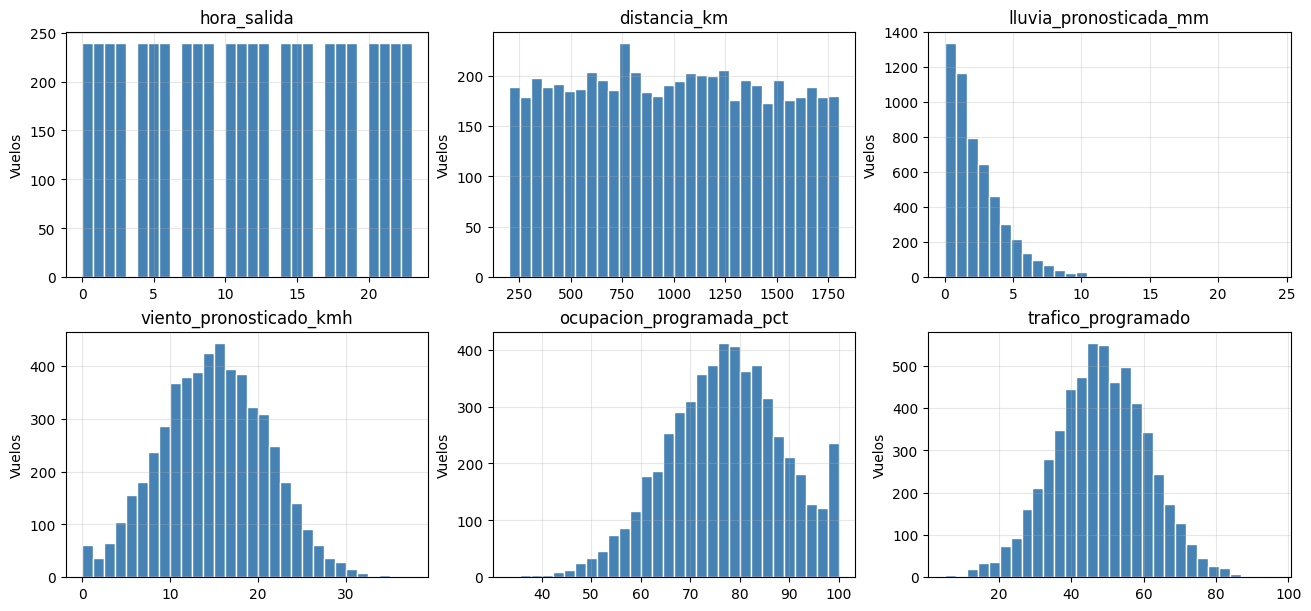

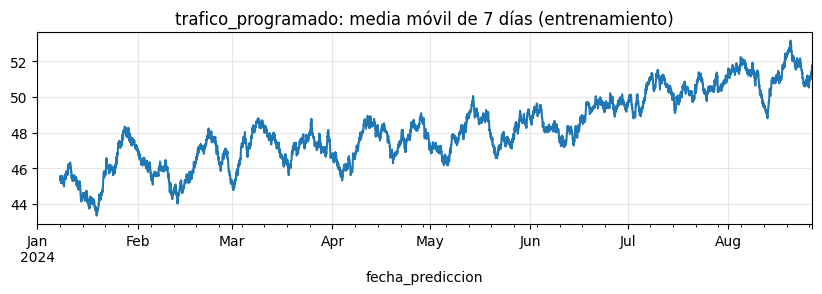

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(13, 6), constrained_layout=True)
for a, col in zip(ax.ravel(), NUMERICAS):
    a.hist(X_ent[col].dropna(), bins=30, color="steelblue", edgecolor="white")
    a.set(title=col, ylabel="Vuelos")
plt.show()

# Tendencia temporal del tráfico dentro de entrenamiento (relevante para la fuga del inciso c).
media_movil = entrenamiento.set_index("fecha_prediccion")["trafico_programado"].rolling(24 * 7).mean()
media_movil.plot(figsize=(10, 2.5), title="trafico_programado: media móvil de 7 días (entrenamiento)")
plt.show()

**Hallazgos de la auditoría.**

- Hay faltantes en `lluvia_pronosticada_mm`, `viento_pronosticado_kmh`, `ocupacion_programada_pct` y `aerolinea` (cerca del 6 % cada una). `origen`, `hora_salida`, `distancia_km` y `trafico_programado` están completas.
- La lluvia tiene cola derecha. El viento y la ocupación están acotados por recortes del generador: viento en $[0,45]$, ocupación en $[25,100]$.
- **Desbalance.** La clase positiva es muy minoritaria, con una prevalencia de 2.4 % en entrenamiento. Por eso el accuracy no sirve como criterio: se usa AP.
- `trafico_programado` crece con el tiempo. Cualquier estadística calculada con datos posteriores (media, mediana) es distinta de la disponible en el pasado.

### Preprocesamiento

Se ajusta **dentro de cada entrenamiento**:

- **Numéricas:** imputación por mediana y estandarización.
- **Categóricas:** imputación por la categoría más frecuente y one-hot con `handle_unknown="ignore"`. Una categoría nueva queda codificada con ceros en todo su bloque.

Se usa scikit-learn para el preprocesamiento, como permite el enunciado.

In [6]:
# Reutilizado de clase: la rama numérica y la categórica de construir_pipeline.
# Mejoras: el estimador final es la logística propia (no la de sklearn).
def construir_preprocesador():
    numerico = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    categorico = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                           ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", numerico, NUMERICAS), ("cat", categorico, CATEGORICAS)])


# Comprobación: un vuelo con aerolínea nueva y lluvia faltante se transforma sin errores.
prep_prueba = construir_preprocesador().fit(X_ent)
vuelo_raro = X_ent.iloc[[0]].copy()
vuelo_raro["aerolinea"] = "Aero_NUEVA"
vuelo_raro["lluvia_pronosticada_mm"] = np.nan
fila = prep_prueba.transform(vuelo_raro)
assert np.all(np.isfinite(fila))
print("Columnas tras preprocesar:", list(prep_prueba.get_feature_names_out()))
print("Vuelo con categoría nueva y faltante ->", np.round(fila, 3))

Columnas tras preprocesar: ['num__hora_salida', 'num__distancia_km', 'num__lluvia_pronosticada_mm', 'num__viento_pronosticado_kmh', 'num__ocupacion_programada_pct', 'num__trafico_programado', 'cat__aerolinea_Aero_A', 'cat__aerolinea_Aero_B', 'cat__aerolinea_Aero_C', 'cat__origen_BOG', 'cat__origen_CLO', 'cat__origen_CTG', 'cat__origen_MDE']
Vuelo con categoría nueva y faltante -> [[-1.372 -0.285 -0.28  -1.654 -0.641 -0.693  0.     0.     0.     0.
   0.     0.     1.   ]]


## 7b. Comparación de modelos con validación cruzada temporal

**Candidatos.** Logística L2 sin ponderar y logística L2 con pesos de clase $a_c=N/(2N_c)$, ambas implementaciones propias. La grilla es $\lambda_2\in\{10^{-3},10^{-2},10^{-1},1,10\}$.

**Objetivo ponderado.** Es una ampliación de `RegresionLogisticaGD.fit(X, y, pesos=a)`:

$$F_a(w,b)=\frac{\sum_n a_{y_n}\,\ell(y_n,z_n)}{\sum_n a_{y_n}}+\frac{\lambda_2}{2}\lVert w\rVert_2^2.$$

- La pérdida se normaliza por $\sum_n a_{y_n}$. Con $a_c=N/(2N_c)$ se cumple $\sum_n a_{y_n}=N_0\frac{N}{2N_0}+N_1\frac{N}{2N_1}=N$, de modo que el peso relativo entre la pérdida y la penalización es el mismo que en el modelo sin ponderar.
- La penalización es la misma, $\frac{\lambda_2}{2}\lVert w\rVert^2$, y el intercepto no se penaliza.
- Los pesos $a_c$ se recalculan con las etiquetas del entrenamiento de cada pliegue.

**Protocolo (fijado antes de ver resultados).**

- **Pliegues.** `TimeSeriesSplit(n_splits=4, gap=24)` dentro de entrenamiento: cada pliegue entrena con el pasado y evalúa en el bloque siguiente. Se verifica que cada evaluación tenga ambas clases.
- **Preprocesamiento.** Se vuelve a ajustar en cada pliegue.
- **Criterio.** AP media entre pliegues, medida sin pesos y sin remuestrear los pliegues evaluados.
- **Desempate.** Si dos candidatos difieren en menos de $10^{-6}$, se prefiere el modelo sin ponderar y, si persiste el empate, el mayor $\lambda_2$.
- **Referencias.** Una probabilidad constante igual a la prevalencia del entrenamiento del pliegue, y la decisión de no emitir alertas.

In [7]:
LAMBDAS = [1e-3, 1e-2, 1e-1, 1.0, 10.0]
TOL_EMPATE = 1e-6
C_FP, C_FN = 1, 12


def pesos_clase(y):
    # a_c = N / (2 N_c), calculado con las etiquetas recibidas.
    conteos = np.bincount(y, minlength=2)
    return (len(y) / (2 * conteos))[y]


def ajustar(X, y, lam2, ponderada):
    # Ajusta preprocesador y logística propia solo con (X, y).
    prep = construir_preprocesador().fit(X)
    modelo = RegresionLogisticaGD(lam2=lam2).fit(prep.transform(X), y,
                                                 pesos=pesos_clase(y) if ponderada else None)
    assert modelo.motivo_parada_ == "convergencia", modelo.motivo_parada_
    return prep, modelo


def probabilidad(prep, modelo, X):
    return modelo.predict_proba(prep.transform(X))[:, 1]


cortes = list(TimeSeriesSplit(n_splits=4, gap=GAP).split(X_ent))
for i_fit, i_eval in cortes:
    assert i_fit.max() + GAP < i_eval.min()
    assert len(np.unique(y_ent[i_eval])) == 2 and len(np.unique(y_ent[i_fit])) == 2
print("Tamaños (ajuste, evaluación, positivos en evaluación):",
      [(len(a), len(b), int(y_ent[b].sum())) for a, b in cortes])

filas = []
for k, (i_fit, i_eval) in enumerate(cortes, start=1):
    X_fit, y_fit, X_eval, y_eval = X_ent.iloc[i_fit], y_ent[i_fit], X_ent.iloc[i_eval], y_ent[i_eval]
    for ponderada in (False, True):
        for lam in LAMBDAS:
            p = probabilidad(*ajustar(X_fit, y_fit, lam, ponderada), X_eval)
            filas.append({"modelo": "ponderada" if ponderada else "sin ponderar", "lambda2": lam,
                          "pliegue": k, "AP": average_precision_score(y_eval, p),
                          "log_loss": log_loss(y_eval, p, labels=[0, 1])})
    # Referencias: probabilidad constante = prevalencia del entrenamiento del pliegue; no alertar.
    p_const = np.full(len(y_eval), y_fit.mean())
    filas.append({"modelo": "referencia: prevalencia", "lambda2": np.nan, "pliegue": k,
                  "AP": average_precision_score(y_eval, p_const), "log_loss": log_loss(y_eval, p_const, labels=[0, 1])})
    filas.append({"modelo": "referencia: no alertar", "lambda2": np.nan, "pliegue": k,
                  "AP": np.nan, "log_loss": np.nan, "recall": 0.0,
                  "costo": C_FN * y_eval.sum() / len(y_eval)})

cv = pd.DataFrame(filas)
cv.to_csv(RESULTADOS / "p7_validacion_cv.csv", index=False)
resumen_cv = (cv.groupby(["modelo", "lambda2"], dropna=False, sort=False)
              .agg(AP_media=("AP", "mean"), AP_desv=("AP", "std"), log_loss_media=("log_loss", "mean"),
                   costo_medio=("costo", "mean"))
              .reset_index())
resumen_cv

Tamaños (ajuste, evaluación, positivos en evaluación): [(1124, 1147, 31), (2271, 1147, 27), (3418, 1147, 31), (4565, 1147, 29)]


,modelo,lambda2,AP_media,AP_desv,log_loss_media,costo_medio
0,sin ponderar,0.001,0.2293,0.0643,0.0946,NaN
1,sin ponderar,0.010,0.2357,0.0825,0.0955,NaN
2,sin ponderar,0.100,0.2157,0.0765,0.1095,NaN
3,sin ponderar,1.000,0.2090,0.0807,0.1185,NaN
4,sin ponderar,10.000,0.2088,0.0802,0.1197,NaN
5,ponderada,0.001,0.2264,0.0719,0.4712,NaN
6,ponderada,0.010,0.2379,0.0815,0.4624,NaN
7,ponderada,0.100,0.2465,0.0998,0.4839,NaN
8,ponderada,1.000,0.2234,0.0869,0.5928,NaN
9,ponderada,10.000,0.2107,0.0810,0.6760,NaN


In [8]:
# AP por pliegue de cada candidato.
cv.assign(lam=cv["lambda2"].fillna("-")).pivot_table(
    index=["modelo", "lam"], columns="pliegue", values="AP", sort=False).round(4)

pliegue                             1       2       3       4
modelo                  lam                                  
sin ponderar            0.001  0.3199  0.1993  0.1722  0.2259
                        0.01   0.3581  0.1805  0.1943  0.2097
                        0.1    0.3275  0.1706  0.2022  0.1625
                        1.0    0.3245  0.1662  0.2020  0.1433
                        10.0   0.3235  0.1662  0.2020  0.1434
ponderada               0.001  0.3263  0.1936  0.1597  0.2258
                        0.01   0.3581  0.1969  0.1799  0.2169
                        0.1    0.3956  0.1892  0.1920  0.2091
                        1.0    0.3510  0.1829  0.2018  0.1581
                        10.0   0.3271  0.1693  0.2017  0.1447
referencia: prevalencia -      0.0270  0.0235  0.0270  0.0253

In [9]:
# Selección con la regla predefinida.
modelos_cv = resumen_cv[~resumen_cv["modelo"].str.startswith("referencia")].copy()
mejor_ap = modelos_cv["AP_media"].max()
empatados = modelos_cv[modelos_cv["AP_media"] >= mejor_ap - TOL_EMPATE].copy()
empatados["orden"] = (empatados["modelo"] != "sin ponderar").astype(int)      # sin ponderar primero
ganador = empatados.sort_values(["orden", "lambda2"], ascending=[True, False]).iloc[0]
GANADOR_PONDERADA, GANADOR_LAMBDA = ganador["modelo"] == "ponderada", float(ganador["lambda2"])

# El otro candidato final: el mejor lambda del tipo de modelo que no ganó.
otro = modelos_cv[modelos_cv["modelo"] != ganador["modelo"]].sort_values(
    ["AP_media", "lambda2"], ascending=[False, False]).iloc[0]

seleccion = {
    "criterio": "AP media en 4 pliegues temporales (gap=24) de entrenamiento",
    "desempate": "diferencia < 1e-6 -> sin ponderar, luego mayor lambda2",
    "historial": modelos_cv.sort_values("AP_media", ascending=False)[
        ["modelo", "lambda2", "AP_media", "AP_desv", "log_loss_media"]].to_dict("records"),
    "ganador": {"modelo": ganador["modelo"], "lambda2": GANADOR_LAMBDA, "AP_media": float(ganador["AP_media"])},
    "otro_candidato_final": {"modelo": otro["modelo"], "lambda2": float(otro["lambda2"]),
                             "AP_media": float(otro["AP_media"])},
}
with open(RESULTADOS / "p7_seleccion.json", "w", encoding="utf-8") as f:
    json.dump(seleccion, f, indent=2, ensure_ascii=False)

print(f"Ganador: logística {ganador['modelo']}, lambda2 = {GANADOR_LAMBDA} (AP media {ganador['AP_media']:.4f})")
print(f"Otro candidato final: logística {otro['modelo']}, lambda2 = {otro['lambda2']} (AP media {otro['AP_media']:.4f})")

Ganador: logística ponderada, lambda2 = 0.1 (AP media 0.2465)
Otro candidato final: logística sin ponderar, lambda2 = 0.01 (AP media 0.2357)


In [10]:
# Comprobación de la equivalencia del objetivo ponderado con scikit-learn:
# sklearn minimiza 1/2 ||w||² + C Σ a_n ℓ_n; dividiendo por C Σ a_n se obtiene F_a con
# lambda2 = 1 / (C Σ a_n), es decir C = 1 / (lambda2 N), y tampoco penaliza el intercepto.
prep_c, propio_c = ajustar(X_ent, y_ent, 0.1, ponderada=True)
sk_c = LogisticRegression(C=1 / (0.1 * len(y_ent)), class_weight="balanced", tol=1e-12,
                          max_iter=10_000).fit(prep_c.transform(X_ent), y_ent)
print("Máx. |Δp| propio vs. sklearn class_weight='balanced':",
      np.max(np.abs(propio_c.predict_proba(prep_c.transform(X_ent))[:, 1]
                    - sk_c.predict_proba(prep_c.transform(X_ent))[:, 1])))

Máx. |Δp| propio vs. sklearn class_weight='balanced': 5.899317312429986e-08


**Interpretación.** 

- **Ganador.** La logística **ponderada con $\lambda_2=0.1$** tiene la mayor AP media (0.2465), frente a 0.2357 de la mejor sin ponderar ($\lambda_2=0.01$). La diferencia (0.011) supera la tolerancia de empate de $10^{-6}$, así que la regla elige la ponderada.
- **La ventaja es frágil.** La desviación entre pliegues es de 0.08 a 0.10, y la ganancia viene casi toda del pliegue 1 (0.396 frente a 0.358). En los pliegues 3 y 4 el modelo sin ponderar es ligeramente mejor. Esa desviación describe diferencias entre períodos, no es un intervalo de confianza.
- **Frente a la referencia.** Todos los modelos superan con amplitud a la probabilidad constante, cuya AP es aproximadamente la prevalencia (0.026). Es decir, ordenan los vuelos unas 9 veces mejor que el azar.
- **Log-loss.** La ponderación empeora mucho la log-loss: 0.46–0.68, frente a 0.095 sin ponderar, peor incluso que la referencia constante (0.120). Los pesos ($a_1/a_0\approx40$) inflan las probabilidades, como predice el problema 3c. La AP no lo detecta porque solo mide el orden.
- **Equivalencia con scikit-learn.** La implementación ponderada coincide con `class_weight="balanced"` (máx. $|\Delta p|\approx6\times10^{-8}$).
- **No alertar** cuesta en promedio 0.309 por vuelo: $12\times$ la prevalencia de cada pliegue.

## 7c. Contraexperimento de fuga y diagnóstico en validación

### Contraexperimento (solo dentro de entrenamiento)

Se mantienen fijos el modelo ganador, su $\lambda_2$ y los 4 pliegues, y se comparan dos procedimientos:

- **Contaminado:** el preprocesador (medianas, modas, medias y escalas) se ajusta una sola vez con **todo** el entrenamiento, antes de la CV. Así, cada pliegue usa estadísticas que incluyen su propio bloque de evaluación y bloques posteriores.
- **Correcto:** el preprocesador se vuelve a ajustar en cada pliegue, solo con su pasado.

Estos resultados contaminados **no** participan en la selección.

In [11]:
prep_global = construir_preprocesador().fit(X_ent)        # contaminado: ve todo entrenamiento
filas = []
for k, (i_fit, i_eval) in enumerate(cortes, start=1):
    X_fit, y_fit, X_eval, y_eval = X_ent.iloc[i_fit], y_ent[i_fit], X_ent.iloc[i_eval], y_ent[i_eval]
    p_ok = probabilidad(*ajustar(X_fit, y_fit, GANADOR_LAMBDA, GANADOR_PONDERADA), X_eval)
    modelo_c = RegresionLogisticaGD(lam2=GANADOR_LAMBDA).fit(
        prep_global.transform(X_fit), y_fit, pesos=pesos_clase(y_fit) if GANADOR_PONDERADA else None)
    p_mal = probabilidad(prep_global, modelo_c, X_eval)
    filas.append({"pliegue": k,
                  "AP correcto": average_precision_score(y_eval, p_ok),
                  "AP contaminado": average_precision_score(y_eval, p_mal),
                  "log-loss correcto": log_loss(y_eval, p_ok), "log-loss contaminado": log_loss(y_eval, p_mal)})
fuga = pd.DataFrame(filas).set_index("pliegue")
fuga["Δ AP (contam. − correcto)"] = fuga["AP contaminado"] - fuga["AP correcto"]
fuga["Δ log-loss (contam. − correcto)"] = fuga["log-loss contaminado"] - fuga["log-loss correcto"]
display(fuga.round(5))

# Qué información se filtró: estadísticas del pliegue 1 frente a las de todo entrenamiento.
i_fit_1 = cortes[0][0]
display(pd.DataFrame({
    "media disponible en el pliegue 1": X_ent.iloc[i_fit_1][NUMERICAS].mean(),
    "media con todo entrenamiento (contaminada)": X_ent[NUMERICAS].mean(),
}).round(3))

,AP correcto,AP contaminado,log-loss correcto,log-loss contaminado,Δ AP (contam. − correcto),Δ log-loss (contam. − correcto)
pliegue,,,,,,
1,0.3956,0.3907,0.4388,0.4366,-0.0049,-2.1600e-03
2,0.1892,0.1858,0.4691,0.4684,-0.0034,-7.0000e-04
3,0.1920,0.1922,0.4781,0.4777,0.0002,-4.0000e-04
4,0.2091,0.2090,0.5497,0.5496,-0.0001,-6.0000e-05


,media disponible en el pliegue 1,media con todo entrenamiento (contaminada)
hora_salida,11.500,11.500
distancia_km,984.975,993.013
lluvia_pronosticada_mm,2.479,2.400
viento_pronosticado_kmh,14.674,14.977
ocupacion_programada_pct,76.684,77.018
trafico_programado,45.785,48.174


**Interpretación.** 

**Diferencias pequeñas.** Las diferencias son mínimas: $|\Delta\text{AP}|\le0.005$ y $|\Delta\text{log-loss}|\le0.002$, y en 3 de los 4 pliegues el procedimiento contaminado obtiene una AP *menor*.

**Hubo fuga de todos modos.** La segunda tabla muestra qué información se usó indebidamente: la media de `trafico_programado` disponible en el pliegue 1 es 45.8, pero el preprocesador contaminado usa 48.2, que incluye vuelos futuros (el tráfico crece con el tiempo).

**¿Por qué el signo o el tamaño de la diferencia no determinan si hay fuga?**

- La fuga es una propiedad del **procedimiento**: qué información estaba disponible al ajustar. No es un efecto que deba verse en la métrica.
- Aquí la información filtrada son medias, escalas y valores de imputación. Cambiarlos equivale casi a una transformación afín de las columnas, que la logística compensa con sus coeficientes y su intercepto. Por eso el efecto es pequeño, y su signo depende del ruido de cada pliegue.
- Con otra transformación, como una codificación por el objetivo o una selección de variables, la misma fuga podría inflar mucho la métrica.
- Una diferencia nula tampoco certifica que el procedimiento sea válido. Lo que lo hace válido es que cada pliegue use solo su pasado.

### Diagnóstico de probabilidades en validación

Los dos candidatos finales (el ganador y el mejor del otro tipo) se ajustan una vez con todo el entrenamiento, preprocesador incluido, y se evalúan en validación. Estos diagnósticos **no cambian el ganador** elegido por CV.

- **AP** es $\sum_k(R_k-R_{k-1})P_k$: suma escalonada de la precisión en cada nuevo nivel de recall.
- **Área trapezoidal bajo PR** interpola linealmente entre los puntos de la curva. Esa interpolación no corresponde a ningún clasificador alcanzable, porque la precisión no varía linealmente entre umbrales. En general da un número distinto de AP, que puede ser mayor o menor.
- **Calibración:** 5 grupos por cuantiles de la probabilidad predicha, con casos y positivos por grupo.

In [12]:
y_val = validacion["retrasado"].to_numpy()
X_val = validacion[PREDICTORES]
finales = {
    f"{'ponderada' if GANADOR_PONDERADA else 'sin ponderar'} λ2={GANADOR_LAMBDA:g} (ganador)":
        ajustar(X_ent, y_ent, GANADOR_LAMBDA, GANADOR_PONDERADA),
    f"{otro['modelo']} λ2={otro['lambda2']:g}":
        ajustar(X_ent, y_ent, float(otro["lambda2"]), otro["modelo"] == "ponderada"),
}
p_val = {nombre: probabilidad(prep, modelo, X_val) for nombre, (prep, modelo) in finales.items()}

filas = []
for nombre, p in p_val.items():
    precision_c, recall_c, _ = precision_recall_curve(y_val, p)
    filas.append({"modelo": nombre, "AP": average_precision_score(y_val, p),
                  "área trapezoidal PR": auc(recall_c, precision_c), "ROC-AUC": roc_auc_score(y_val, p),
                  "log-loss": log_loss(y_val, p), "Brier": brier_score_loss(y_val, p),
                  "probabilidad media": p.mean()})
print(f"Prevalencia en validación: {y_val.mean():.4f} ({y_val.sum()} positivos de {len(y_val)})")
pd.DataFrame(filas).set_index("modelo")

Prevalencia en validación: 0.0390 (74 positivos de 1896)


,AP,área trapezoidal PR,ROC-AUC,log-loss,Brier,probabilidad media
modelo,,,,,,
ponderada λ2=0.1 (ganador),0.3939,0.3917,0.8528,0.5351,0.1784,0.3916
sin ponderar λ2=0.01,0.3915,0.3891,0.8512,0.1259,0.0316,0.0302


ponderada λ2=0.1 (ganador): 5 grupos efectivos


,casos,positivos,p_media,frecuencia
grupo,,,,
"(0.0271, 0.209]",380,0,0.1501,0.0000
"(0.209, 0.305]",379,2,0.2582,0.0053
"(0.305, 0.42]",379,9,0.3602,0.0237
"(0.42, 0.57]",379,9,0.4899,0.0237
"(0.57, 0.989]",379,54,0.7003,0.1425


sin ponderar λ2=0.01: 5 grupos efectivos


,casos,positivos,p_media,frecuencia
grupo,,,,
"(-0.000227, 0.00767]",380,0,0.0051,0.0000
"(0.00767, 0.0127]",379,2,0.0101,0.0053
"(0.0127, 0.0214]",379,9,0.0166,0.0237
"(0.0214, 0.04]",379,10,0.0290,0.0264
"(0.04, 0.815]",379,53,0.0902,0.1398


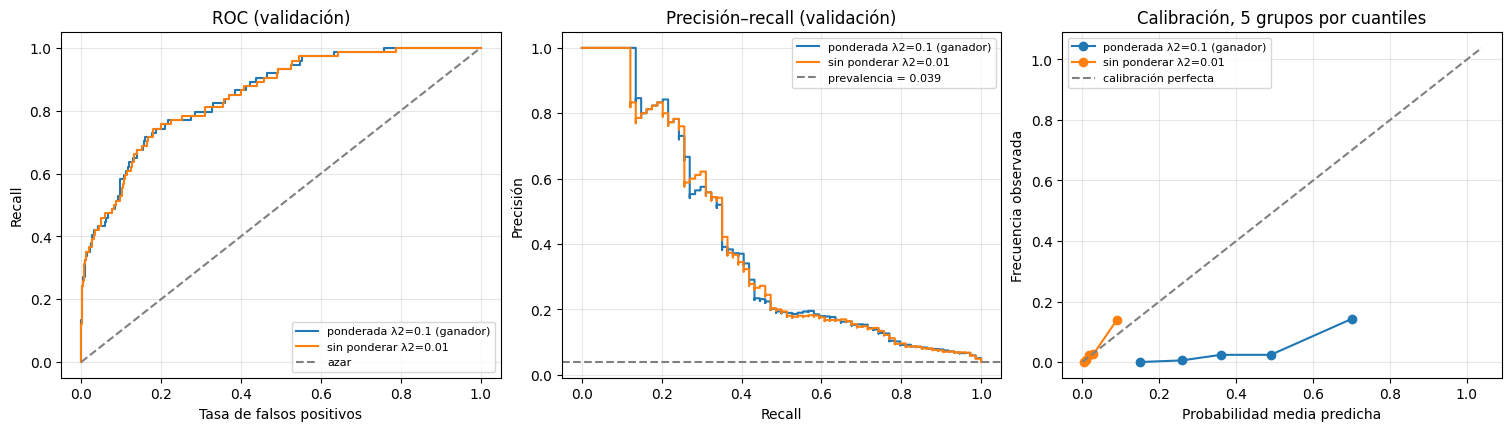

In [13]:
def tabla_calibracion(y, p, grupos=5):
    # Grupos por cuantiles de p; si hay probabilidades repetidas, qcut puede fusionar grupos.
    grupo = pd.qcut(p, grupos, duplicates="drop")
    return (pd.DataFrame({"y": y, "p": p, "grupo": grupo})
            .groupby("grupo", observed=True)
            .agg(casos=("y", "size"), positivos=("y", "sum"), p_media=("p", "mean"), frecuencia=("y", "mean")))


fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
for nombre, p in p_val.items():
    fpr, tpr, _ = roc_curve(y_val, p)
    precision_c, recall_c, _ = precision_recall_curve(y_val, p)
    ax[0].plot(fpr, tpr, label=nombre)
    ax[1].step(recall_c, precision_c, where="post", label=nombre)
    cal = tabla_calibracion(y_val, p)
    ax[2].plot(cal["p_media"], cal["frecuencia"], "o-", label=nombre)
    print(f"{nombre}: {len(cal)} grupos efectivos")
    display(cal.round(4))
ax[0].plot([0, 1], [0, 1], "--", color="gray", label="azar")
ax[0].set(xlabel="Tasa de falsos positivos", ylabel="Recall", title="ROC (validación)")
ax[1].axhline(y_val.mean(), ls="--", color="gray", label=f"prevalencia = {y_val.mean():.3f}")
ax[1].set(xlabel="Recall", ylabel="Precisión", title="Precisión–recall (validación)")
lim = max(max(p.max() for p in p_val.values()), y_val.mean()) * 1.05
ax[2].plot([0, lim], [0, lim], "--", color="gray", label="calibración perfecta")
ax[2].set(xlabel="Probabilidad media predicha", ylabel="Frecuencia observada", title="Calibración, 5 grupos por cuantiles")
for a in ax:
    a.legend(fontsize=8)
plt.show()

**Interpretación.** 

**Ordenamiento.** Los dos candidatos ordenan casi igual en validación: AP 0.394 frente a 0.392, ROC-AUC 0.853 frente a 0.851, y las curvas ROC y PR prácticamente superpuestas. AP (0.3939) y el área trapezoidal (0.3917) difieren, como se explicó arriba.

**Calibración.** Aquí está la diferencia importante entre los dos candidatos:

- **Ponderada.** Su probabilidad media es 0.392, frente a una prevalencia de 0.039. Las probabilidades son unas 10 veces mayores que la frecuencia real. En el grupo más alto predice 0.70 y la frecuencia observada es 0.14, y toda su curva queda muy por debajo de la diagonal. Log-loss 0.535 y Brier 0.178.
- **Sin ponderar.** Su probabilidad media es 0.030 y sus grupos están cerca de la diagonal. Solo subestima en el grupo más alto: 0.090 frente a 0.140. Log-loss 0.126 y Brier 0.032.

Es exactamente el resultado del problema 3c. Con pesos $a_1,a_0$, el minimizador poblacional es $q^\star=\frac{a_1p}{a_1p+a_0(1-p)}\neq p$, y con $a_1/a_0\approx40$ las probabilidades se desplazan hacia arriba.

En los dos modelos los 5 grupos por cuantiles son efectivos, porque no hay probabilidades repetidas que obliguen a fusionarlos. Conforme a la regla, **el ganador sigue siendo la logística ponderada**: la CV la eligió por AP, y estos diagnósticos no cambian la elección.

## 7d. Política de alertas en validación

Las probabilidades de validación del ganador quedan fijas. La regla es $\hat y=\mathbb 1\{p\ge\tau\}$, y se evalúan:

- todos los valores únicos predichos como umbral;
- **"alertar todos"** ($\tau=0$);
- **"no alertar ninguno"**, implementada como $\tau=+\infty$. Así sigue siendo correcta aunque alguna probabilidad redondee a 1.

La columna `modo` marca las dos políticas extremas.

**Condiciones operativas del taller:** recall $\ge0.80$, tasa de alertas $(TP+FP)/N_{val}\le0.15$ y costo $\hat C(\tau)=(12\,FN+FP)/N_{val}$.

**Regla de elección.** Entre las políticas factibles, la de menor costo; en empate, la de menor tasa de alertas y después la de mayor umbral. Si ninguna es factible, el resultado es **inviabilidad empírica**: se reportan el máximo recall con hasta 15 % de alertas y la menor tasa de alertas que alcanza recall 0.80, y se congela como referencia diagnóstica (no como política aprobada) el umbral de menor costo sin restricciones.

**Comparaciones.**

- $\tau=0.5$.
- El umbral teórico del problema 3b, $\tau^\star=C_{FP}/(C_{FP}+C_{FN})=1/13\approx0.0769$. Ese umbral minimiza el costo esperado **solo si $p$ es la probabilidad verdadera** $P(Y=1\mid x)$. Con probabilidades estimadas, y posiblemente mal calibradas, no hay garantía.

In [14]:
RECALL_MIN, TASA_MAX = 0.80, 0.15
TAU_TEORICO = C_FP / (C_FP + C_FN)
NOMBRE_GANADOR = next(iter(finales))
prep_g, modelo_g = finales[NOMBRE_GANADOR]
p_g = p_val[NOMBRE_GANADOR]


def conteos(y, alerta):
    # TP, FP, FN, TN calculados directamente con NumPy.
    return (int(np.sum(alerta & (y == 1))), int(np.sum(alerta & (y == 0))),
            int(np.sum(~alerta & (y == 1))), int(np.sum(~alerta & (y == 0))))


def fila_politica(y, p, tau, modo="umbral"):
    alerta = p >= tau
    tp, fp, fn, tn = conteos(y, alerta)
    return {"tau": tau, "modo": modo, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "recall": tp / (tp + fn), "precision": tp / (tp + fp) if tp + fp else np.nan,
            "tasa_alertas": (tp + fp) / len(y), "costo": (C_FN * fn + C_FP * fp) / len(y)}


umbrales = pd.DataFrame(
    [fila_politica(y_val, p_g, 0.0, "alertar_todos")]
    + [fila_politica(y_val, p_g, t) for t in np.unique(p_g)]
    + [fila_politica(y_val, p_g, np.inf, "no_alertar")])
umbrales["factible"] = (umbrales["recall"] >= RECALL_MIN) & (umbrales["tasa_alertas"] <= TASA_MAX)
assert (umbrales[["TP", "FP", "FN", "TN"]].sum(axis=1) == len(y_val)).all()
umbrales.to_csv(RESULTADOS / "p7_tabla_umbrales.csv", index=False)

orden = ["costo", "tasa_alertas", "tau"]
factibles = umbrales[umbrales["factible"]]
if len(factibles):
    ESTADO = "factible"
    politica = factibles.sort_values(orden, ascending=[True, True, False]).iloc[0]
else:
    ESTADO = "inviabilidad empírica"
    max_recall = umbrales[umbrales["tasa_alertas"] <= TASA_MAX].sort_values(
        ["recall", "tasa_alertas"], ascending=[False, True]).iloc[0]
    min_tasa = umbrales[umbrales["recall"] >= RECALL_MIN].sort_values(
        ["tasa_alertas", "tau"], ascending=[True, False]).iloc[0]
    politica = umbrales.sort_values(orden, ascending=[True, True, False]).iloc[0]   # diagnóstica

print(f"Políticas evaluadas: {len(umbrales)} | factibles: {len(factibles)} | estado: {ESTADO}")
comparacion = pd.DataFrame(
    {("seleccionada" if ESTADO == "factible" else "diagnóstica (menor costo sin restricciones)"): politica,
     "tau = 0.5": pd.Series(fila_politica(y_val, p_g, 0.5)),
     "tau teórico = 1/13": pd.Series(fila_politica(y_val, p_g, TAU_TEORICO))}).T
if ESTADO != "factible":
    comparacion.loc["máximo recall con tasa <= 0.15"] = max_recall
    comparacion.loc["menor tasa con recall >= 0.80"] = min_tasa
comparacion[["tau", "modo", "TP", "FP", "FN", "TN", "recall", "precision", "tasa_alertas", "costo"]]

Políticas evaluadas: 1898 | factibles: 0 | estado: inviabilidad empírica


,tau,modo,TP,FP,FN,TN,recall,precision,tasa_alertas,costo
diagnóstica (menor costo sin restricciones),0.6351,umbral,47,219,27,1603,0.6351,0.1767,0.1403,0.2864
tau = 0.5,0.5,umbral,57,474,17,1348,0.7703,0.1073,0.2801,0.3576
tau teórico = 1/13,0.0769,umbral,74,1794,0,28,1.0,0.0396,0.9852,0.9462
máximo recall con tasa <= 0.15,0.6351,umbral,47,219,27,1603,0.6351,0.1767,0.1403,0.2864
menor tasa con recall >= 0.80,0.4546,umbral,60,596,14,1226,0.8108,0.0915,0.346,0.403


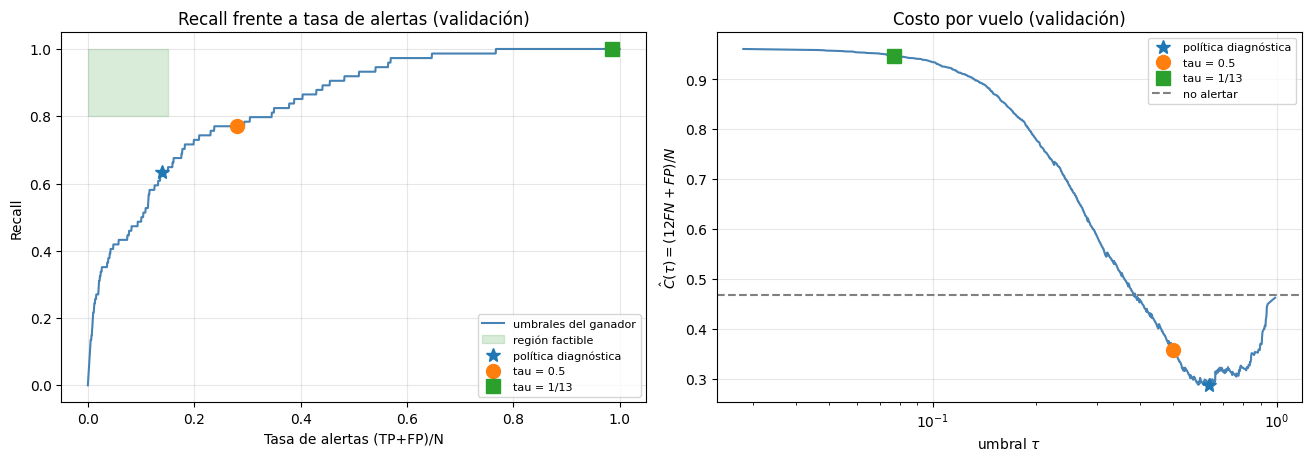

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
ax[0].plot(umbrales["tasa_alertas"], umbrales["recall"], "-", color="steelblue", label="umbrales del ganador")
ax[0].fill_between([0, TASA_MAX], RECALL_MIN, 1.0, color="green", alpha=0.15, label="región factible")
marcas = {"política diagnóstica" if ESTADO != "factible" else "política seleccionada": politica,
          "tau = 0.5": comparacion.loc["tau = 0.5"], "tau = 1/13": comparacion.loc["tau teórico = 1/13"]}
for (nombre, fila), m in zip(marcas.items(), ["*", "o", "s"]):
    ax[0].plot(fila["tasa_alertas"], fila["recall"], m, ms=10, label=nombre)
ax[0].set(xlabel="Tasa de alertas (TP+FP)/N", ylabel="Recall", title="Recall frente a tasa de alertas (validación)")
ax[0].legend(fontsize=8)

t = umbrales[umbrales["modo"] == "umbral"]
ax[1].plot(t["tau"], t["costo"], color="steelblue")
for (nombre, fila), m in zip(marcas.items(), ["*", "o", "s"]):
    ax[1].plot(fila["tau"], fila["costo"], m, ms=10, label=nombre)
ax[1].axhline(umbrales.query("modo == 'no_alertar'")["costo"].item(), ls="--", color="gray", label="no alertar")
ax[1].set(xscale="log", xlabel=r"umbral $\tau$", ylabel=r"$\hat C(\tau)=(12FN+FP)/N$", title="Costo por vuelo (validación)")
ax[1].legend(fontsize=8)
plt.show()

**Interpretación.** 

**Resultado: inviabilidad empírica.** Ninguna de las 1898 políticas evaluadas cumple a la vez recall $\ge0.80$ y alertas $\le15\,\%$:

- **Máximo recall con hasta 15 % de alertas:** 0.635 ($\tau=0.6351$, 14.0 % de alertas).
- **Menor tasa de alertas con recall $\ge0.80$:** 34.6 % ($\tau=0.4546$, recall 0.811).

Para cumplir ambas condiciones con 74 positivos en 1896 vuelos haría falta una precisión de al menos $0.8\times0.039/0.15\approx0.21$ con recall 0.80. El modelo solo alcanza 0.09 en ese punto. Las restricciones no son compatibles con el ordenamiento que logra este modelo. No se cambian los límites ni los datos.

**Referencia diagnóstica (no aprobada).** El umbral de menor costo sin restricciones es $\tau=0.6351$, con costo 0.286 por vuelo, frente a 0.469 de no alertar y 0.358 de $\tau=0.5$. En esta ejecución coincide con la política de máximo recall dentro del 15 % de alertas.

**Comparaciones.**

- **$\tau=0.5$:** recall 0.770 con 28 % de alertas.
- **$\tau^\star=1/13$:** alerta al 98.5 % de los vuelos, con costo 0.946, casi igual a alertar a todos.

El umbral teórico falla porque supone que $p$ es la probabilidad verdadera, y las probabilidades del modelo ponderado están infladas unas 10 veces. Si se traslada $\tau^\star$ a la escala ponderada con la relación del problema 3c, $\tau_q=\frac{a_1\tau^\star}{a_1\tau^\star+a_0(1-\tau^\star)}$ con $a_1/a_0=N_0/N_1\approx40$, se obtiene $\tau_q\approx0.77$. Ese valor está en la misma zona que el umbral empírico de menor costo (0.635). La corrección no es exacta porque el modelo es restringido, está regularizado y se estimó con una muestra finita, así que $q^\star$ poblacional solo se cumple aproximadamente.

## 7e. Manifiesto y evaluación final en prueba

**Antes** de abrir prueba se guarda el manifiesto con:

- variables;
- preprocesamiento, con las estadísticas aprendidas;
- parámetros del modelo;
- regla de decisión;
- umbrales sin redondear. JSON escribe cada float con todos sus dígitos.

El modelo **no** se reentrena con entrenamiento más validación: hacerlo cambiaría las probabilidades sobre las que se eligió el umbral.

In [16]:
num = prep_g.named_transformers_["num"]
cat = prep_g.named_transformers_["cat"]
POLITICAS = {"tau_0.5": 0.5, "tau_teorico": TAU_TEORICO,
             ("tau_seleccionado" if ESTADO == "factible" else "tau_diagnostico"): float(politica["tau"])}
manifiesto = {
    "variables": PREDICTORES,
    "preprocesamiento": {
        "numericas": {"variables": NUMERICAS, "imputacion_mediana": num["imputar"].statistics_.tolist(),
                      "media": num["escalar"].mean_.tolist(), "escala": num["escalar"].scale_.tolist()},
        "categoricas": {"variables": CATEGORICAS, "imputacion_moda": cat["imputar"].statistics_.tolist(),
                        "categorias": [c.tolist() for c in cat["codificar"].categories_],
                        "categoria_nueva": "bloque one-hot en ceros"},
        "ajustado_con": "entrenamiento (ids %d-%d)" % (entrenamiento["id_vuelo"].min(), entrenamiento["id_vuelo"].max()),
    },
    "modelo": {"clase": "RegresionLogisticaGD", "ponderada": bool(GANADOR_PONDERADA), "lambda2": GANADOR_LAMBDA,
               "columnas": prep_g.get_feature_names_out().tolist(),
               "coef": modelo_g.coef_.tolist(), "intercept": modelo_g.intercept_},
    "regla": "alerta si p >= tau",
    "estado_politica": ESTADO,
    "politicas": POLITICAS,
    "restricciones": {"recall_min": RECALL_MIN, "tasa_alertas_max": TASA_MAX, "costo": "(12 FN + FP) / N"},
}
RUTA_MANIFIESTO = RESULTADOS / "p7_manifiesto_politica.json"
with open(RUTA_MANIFIESTO, "w", encoding="utf-8") as f:
    json.dump(manifiesto, f, indent=2, ensure_ascii=False)
modelo_g.guardar_parametros(PARAMETROS / "p7_logistica.json")
print(json.dumps(POLITICAS, indent=2))

{
  "tau_0.5": 0.5,
  "tau_teorico": 0.07692307692307693,
  "tau_diagnostico": 0.6351112455227611
}


### Evaluación única en prueba

Las probabilidades de prueba se calculan una sola vez con el modelo congelado. Los umbrales se leen del manifiesto guardado.

- $TP, TN, FP, FN$ se cuentan con NumPy y se verifican contra `confusion_matrix` de scikit-learn.
- Las métricas que solo dependen de las probabilidades (AP, ROC-AUC, log-loss, Brier) deben ser idénticas para las tres políticas.

In [17]:
with open(RUTA_MANIFIESTO, encoding="utf-8") as f:
    politicas_congeladas = json.load(f)["politicas"]

X_pru, y_pru = prueba[PREDICTORES], prueba["retrasado"].to_numpy()
p_pru = probabilidad(prep_g, modelo_g, X_pru)          # única pasada por prueba

filas = []
for nombre, tau in politicas_congeladas.items():
    alerta = p_pru >= tau
    tp, fp, fn, tn = conteos(y_pru, alerta)
    assert np.array_equal(confusion_matrix(y_pru, alerta.astype(int), labels=[0, 1]).ravel(), [tn, fp, fn, tp])
    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn)
    fila = {"política": nombre, "tau": tau, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "precision": precision, "recall": recall, "especificidad": tn / (tn + fp),
            "F1": 2 * tp / (2 * tp + fp + fn), "accuracy": (tp + tn) / len(y_pru),
            "AP": average_precision_score(y_pru, p_pru), "ROC-AUC": roc_auc_score(y_pru, p_pru),
            "log-loss": log_loss(y_pru, p_pru), "Brier": brier_score_loss(y_pru, p_pru),
            "costo": (C_FN * fn + C_FP * fp) / len(y_pru), "alertas por 1000": 1000 * (tp + fp) / len(y_pru)}
    # Verificación contra scikit-learn de las métricas de decisión.
    np.testing.assert_allclose([fila["precision"], recall, fila["F1"], fila["accuracy"]],
                               [precision_score(y_pru, alerta, zero_division=np.nan), recall_score(y_pru, alerta),
                                f1_score(y_pru, alerta), accuracy_score(y_pru, alerta)])
    fila["cumple recall >= 0.80"] = recall >= RECALL_MIN
    fila["cumple alertas <= 15 %"] = (tp + fp) / len(y_pru) <= TASA_MAX
    filas.append(fila)

final = pd.DataFrame(filas).set_index("política")
for metrica in ("AP", "ROC-AUC", "log-loss", "Brier"):          # no dependen del umbral
    assert final[metrica].nunique() == 1
final.to_csv(RESULTADOS / "p7_evaluacion_final.csv")

salida = prueba[["id_vuelo", "fecha_prediccion", "retrasado"]].copy()
salida["probabilidad"] = p_pru
for nombre, tau in politicas_congeladas.items():
    salida[f"alerta_{nombre}"] = (p_pru >= tau).astype(int)
salida.to_csv(RESULTADOS / "p7_predicciones_prueba.csv", index=False)

print(f"Prevalencia en prueba: {y_pru.mean():.4f} ({y_pru.sum()} positivos de {len(y_pru)})")
final.T

Prevalencia en prueba: 0.0370 (71 positivos de 1920)


política,tau_0.5,tau_teorico,tau_diagnostico
tau,0.5,0.0769,0.6351
TP,57,71,50
FP,565,1821,234
FN,14,0,21
TN,1284,28,1615
precision,0.0916,0.0375,0.1761
recall,0.8028,1.0,0.7042
especificidad,0.6944,0.0151,0.8734
F1,0.1645,0.0723,0.2817
accuracy,0.6984,0.0516,0.8672


**Interpretación.** 

**Verificaciones.** Prueba tiene 71 positivos en 1920 vuelos (prevalencia 3.70 %). Los conteos de NumPy coinciden con `confusion_matrix`, y precision, recall, F1 y accuracy coinciden con scikit-learn. AP (0.409), ROC-AUC (0.869), log-loss (0.561) y Brier (0.191) son idénticos para las tres políticas, porque solo dependen de las probabilidades y no del umbral.

**Resultados por política.**

| Política | Recall | Alertas por 1000 | Costo | ¿Cumple ambas restricciones? |
|---|---|---|---|---|
| Diagnóstica ($\tau=0.6351$) | 0.704 | 148 | 0.253 (el menor) | No: cumple alertas, no recall |
| $\tau=0.5$ | 0.803 | 324 | 0.382 | No: cumple recall, no alertas |
| $\tau^\star=1/13$ | 1.0 | 985 | 0.948 | No: alerta casi a todos |

Ninguna política cumple las dos restricciones a la vez, lo que es coherente con la inviabilidad encontrada en validación.

**¿Por qué cumplir en validación no garantizaba cumplir en prueba?** Las métricas también se movieron entre validación y prueba: el recall de la política diagnóstica subió de 0.635 a 0.704, y el de $\tau=0.5$ de 0.770 a 0.803. Hay tres razones:

1. **Pocos positivos.** Con unos 70 positivos por período, el error estándar del recall es de aproximadamente $\sqrt{0.7\cdot0.3/71}\approx0.05$.
2. **Cambio de período.** Prueba es un período posterior: el tráfico programado sigue creciendo con el tiempo, y la prevalencia y la distribución de los scores cambian.
3. **Optimismo de la selección.** El umbral se eligió optimizando sobre validación, así que su desempeño allí es optimista.

Por eso una restricción satisfecha en validación es solo una estimación para el siguiente período. La política no se ajusta después de observar estos resultados.